# UPI Fraud Detection - XGBoost (Production-Ready)

This notebook implements a production-ready XGBoost model with:
- Hyperparameter tuning using RandomizedSearchCV with stratified cross-validation
- Threshold optimization for balanced precision-recall
- Comprehensive evaluation metrics and visualizations
- SHAP explainability for fraud predictions
- Complete pipeline saving for MERN backend integration

Workflow:
1. Load and preprocess data
2. Hyperparameter tuning with RandomizedSearchCV
3. Train best model on full training data
4. Threshold optimization
5. Comprehensive evaluation
6. SHAP explainability
7. Save production artifacts

## 1. Imports and Configuration

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import joblib
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, 
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
import shap

# Configuration
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)

DATA_PATH = Path('..') / 'dataset' / 'upi_fraud_dataset_behavioral_v2.csv'
MODELS_DIR = Path('..') / 'models'
MODELS_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 42

,transaction_id,transaction_date,transaction_time,customer_id,sender_upi,receiver_upi,amount,transaction_type,merchant_category,sender_account_age_days,receiver_account_age_days,device_id,device_changed,known_device,trusted_device,os_type,app_name,ip_address,location,location_changed,new_beneficiary,beneficiary_frequency,transactions_last_10_minutes,transactions_last_hour,transactions_last_24_hours,amount_sent_last_24_hours,amount_received_last_24_hours,unique_receivers_today,balance_before,balance_after,decimal_pattern,money_flow_pattern,customer_behaviour_deviation,is_fraud,fraud_type
0,TXN0096196,2026-04-07,00:07:47,CUST02924,ishaantank6535@okhdfcbank,vsingh6378@paytm,745.21,P2P,NaN,124,235,DEV-48EA6BD0FFEE,False,True,True,Android,Paytm,58.35.75.178,Pune,False,True,0,0,0,0,0.0,0.0,0,44705.71,43960.50,False,Refund,0.2219,0,NaN
1,TXN0067907,2026-04-07,00:08:45,CUST04012,harinakshikar7902@oksbi,bahadurjitchandran9738@okhdfcbank,1230.44,P2M,Electronics,308,146,DEV-B7CD99AC4D9B,False,True,True,Android,Paytm,171.220.144.175,Mumbai,False,True,0,0,0,0,0.0,0.0,0,1269254.65,1268024.21,False,Travel Payment,0.1813,0,NaN
2,TXN0008569,2026-04-07,00:10:50,CUST02392,sathvikswamy9935@paytm,lavanyasen2814@okaxis,643.95,P2P,NaN,113,322,DEV-CDC3A225D3F6,False,True,True,Android,Paytm,130.196.162.207,Lucknow,False,True,0,0,0,0,0.0,0.0,0,343755.85,343111.90,False,Gift,0.4219,0,NaN
3,TXN0083623,2026-04-07,00:13:39,CUST01883,aayushwali4880@paytm,finnchanda3055@okicici,203.08,P2P,NaN,627,1098,DEV-3766EBCA617C,False,True,True,iOS,AmazonPay,79.123.13.235,Nagpur,False,True,0,0,0,0,0.0,0.0,0,261606.72,261403.64,False,Personal Transfer,0.2455,0,NaN
4,TXN0060281,2026-04-07,00:20:18,CUST04883,amritalalla5990@okicici,merchant8860@apl,401.43,P2M,Rent,1000,266,DEV-B50D1ADAFF11,False,True,True,Android,BHIM,92.106.65.184,Jaipur,False,True,0,0,0,0,0.0,0.0,0,120217.53,119816.10,False,Bills Payment,0.1768,0,NaN


## 2. Load Dataset

In [ ]:
df = pd.read_csv(DATA_PATH)
print(f'Dataset shape: {df.shape}')
print(f'\nTarget distribution:')
print(df['is_fraud'].value_counts().rename(index={0: 'Legit', 1: 'Fraud'}))
print(f'\nFraud rate: {df["is_fraud"].mean():.4%}')

Encoded feature shape: (100000, 76)


## 3. Preprocessing Function

This function handles all preprocessing steps consistently.

In [ ]:
def preprocess_data(df):
    """
    Preprocess the UPI fraud dataset.
    
    Args:
        df: Raw dataframe
        
    Returns:
        X_encoded: Processed feature matrix
        y: Target variable
        feature_columns: List of feature column names
    """
    # Drop identifier columns
    target_column = 'is_fraud'
    identifier_columns = [
        'transaction_id', 'customer_id', 'sender_upi', 
        'receiver_upi', 'device_id', 'ip_address', 'fraud_type'
    ]
    
    available_identifier_columns = [col for col in identifier_columns if col in df.columns]
    data = df.drop(columns=available_identifier_columns).copy()
    
    # Separate target and features
    y = data[target_column].copy()
    X = data.drop(columns=[target_column]).copy()
    
    # Extract datetime features
    transaction_date = pd.to_datetime(X['transaction_date'], errors='coerce')
    X['transaction_dayofweek'] = transaction_date.dt.dayofweek
    X['transaction_day'] = transaction_date.dt.day
    X['transaction_month'] = transaction_date.dt.month
    X['transaction_year'] = transaction_date.dt.year
    X['transaction_hour'] = pd.to_datetime(X['transaction_time'], format='%H:%M:%S', errors='coerce').dt.hour
    X = X.drop(columns=['transaction_date', 'transaction_time'])
    
    # Handle missing values
    categorical_columns = X.select_dtypes(include=['object', 'bool']).columns.tolist()
    numeric_columns = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
    
    for column in categorical_columns:
        if column == 'merchant_category':
            X[column] = X[column].fillna('P2P')
        else:
            X[column] = X[column].fillna('NONE')
    
    for column in numeric_columns:
        X[column] = X[column].fillna(X[column].median())
    
    # One-hot encode categorical features
    X_encoded = pd.get_dummies(X, columns=categorical_columns, drop_first=False)
    feature_columns = X_encoded.columns.tolist()
    
    return X_encoded, y, feature_columns

# Apply preprocessing
X_encoded, y, feature_columns = preprocess_data(df)
print(f'Processed feature shape: {X_encoded.shape}')
print(f'Target shape: {y.shape}')

X_train shape: (80000, 76)
X_test shape: (20000, 76)


## 4. Train/Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f'X_train shape: {X_train.shape}')
print(f'X_test shape: {X_test.shape}')
print(f'y_train fraud rate: {y_train.mean():.4%}')
print(f'y_test fraud rate: {y_test.mean():.4%}')

## 5. Hyperparameter Tuning with RandomizedSearchCV

We use stratified cross-validation and optimize for F1 score to balance precision and recall.

            XGBoost
Accuracy   0.884050
Precision  0.261483
Recall     0.723000
F1 Score   0.384064
ROC-AUC    0.874982

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.89      0.94     19000
           1       0.26      0.72      0.38      1000

    accuracy                           0.88     20000
   macro avg       0.62      0.81      0.66     20000
weighted avg       0.95      0.88      0.91     20000



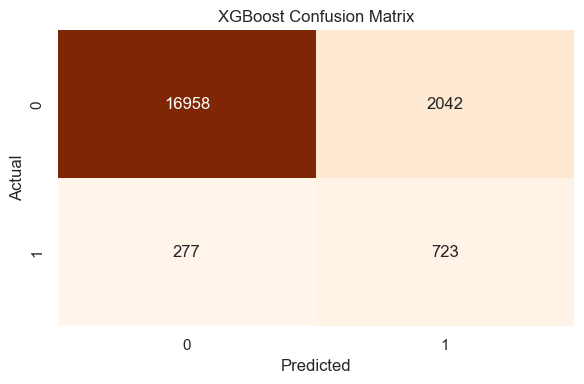

In [ ]:
# Calculate scale_pos_weight for class imbalance
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f'Scale positive weight: {scale_pos_weight:.2f}')

# Define hyperparameter search space
param_distributions = {
    'n_estimators': [100, 200, 300, 400, 500],
    'max_depth': [3, 4, 5, 6, 7, 8],
    'learning_rate': [0.01, 0.05, 0.1, 0.15, 0.2],
    'min_child_weight': [1, 2, 3, 4, 5],
    'gamma': [0, 0.1, 0.2, 0.3, 0.4],
    'subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'reg_alpha': [0, 0.01, 0.1, 1],
    'reg_lambda': [0, 0.01, 0.1, 1]
}

# Base XGBoost model
xgb_base = XGBClassifier(
    tree_method='hist',
    random_state=RANDOM_STATE,
    n_jobs=-1,
    eval_metric='logloss',
    scale_pos_weight=scale_pos_weight
)

# Stratified K-Fold for cross-validation
stratified_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_distributions,
    n_iter=50,
    cv=stratified_cv,
    scoring='f1',
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=1
)

print('Starting hyperparameter tuning...')
random_search.fit(X_train, y_train)

print(f'\nBest F1 Score (CV): {random_search.best_score_:.4f}')
print(f'\nBest Hyperparameters:')
best_params = random_search.best_params_
for param, value in best_params.items():
    print(f'  {param}: {value}')

In [ ]:
# Train final model with best parameters
best_xgb = XGBClassifier(
    **best_params,
    tree_method='hist',
    random_state=RANDOM_STATE,
    n_jobs=-1,
    eval_metric='logloss',
    scale_pos_weight=scale_pos_weight
)

best_xgb.fit(X_train, y_train)

# Generate predictions
y_pred = best_xgb.predict(X_test)
y_proba = best_xgb.predict_proba(X_test)[:, 1]

print('Model training completed.')

## 7. Threshold Optimization

We test multiple thresholds to find the optimal balance between precision and recall.

In [ ]:
# Test thresholds from 0.20 to 0.60
thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]
threshold_results = []

for threshold in thresholds:
    y_pred_thresh = (y_proba >= threshold).astype(int)
    precision = precision_score(y_test, y_pred_thresh, zero_division=0)
    recall = recall_score(y_test, y_pred_thresh, zero_division=0)
    f1 = f1_score(y_test, y_pred_thresh, zero_division=0)
    
    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })

threshold_df = pd.DataFrame(threshold_results)
print('Threshold Optimization Results:')
print(threshold_df.to_string(index=False))

# Select best threshold based on F1 score
best_threshold_row = threshold_df.loc[threshold_df['F1 Score'].idxmax()]
best_threshold = best_threshold_row['Threshold']
print(f'\nBest Threshold: {best_threshold}')
print(f'Best F1 Score: {best_threshold_row["F1 Score"]:.4f}')

## 8. Comprehensive Evaluation with Best Threshold

In [ ]:
# Use best threshold for final predictions
y_pred_best = (y_proba >= best_threshold).astype(int)

# Calculate metrics
metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_best),
    'Precision': precision_score(y_test, y_pred_best, zero_division=0),
    'Recall': recall_score(y_test, y_pred_best, zero_division=0),
    'F1 Score': f1_score(y_test, y_pred_best, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, y_proba),
}

metrics_df = pd.DataFrame(metrics, index=['XGBoost (Optimized)']).T
print('Final Model Metrics:')
print(metrics_df)

print('\nClassification Report:')
print(classification_report(y_test, y_pred_best, zero_division=0))

## 9. Visualization: ROC Curve

In [ ]:
fpr, tpr, _ = roc_curve(y_test, y_proba)

plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, linewidth=2, label=f'XGBoost (AUC = {roc_auc_score(y_test, y_proba):.4f})')
plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random Classifier')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curve - XGBoost Model', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Visualization: Precision-Recall Curve

In [ ]:
precision, recall, _ = precision_recall_curve(y_test, y_proba)

plt.figure(figsize=(10, 6))
plt.plot(recall, precision, linewidth=2, label='XGBoost')
plt.xlabel('Recall', fontsize=12)
plt.ylabel('Precision', fontsize=12)
plt.title('Precision-Recall Curve - XGBoost Model', fontsize=14, fontweight='bold')
plt.legend(loc='best', fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Visualization: Confusion Matrix

In [ ]:
cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, 
            annot_kws={'size': 14, 'weight': 'bold'})
plt.title(f'Confusion Matrix (Threshold = {best_threshold})', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.xticks([0.5, 1.5], ['Legitimate', 'Fraud'], fontsize=11)
plt.yticks([0.5, 1.5], ['Legitimate', 'Fraud'], fontsize=11)
plt.tight_layout()
plt.show()

## 12. Visualization: Feature Importance (Top 20)

In [ ]:
# Get feature importance
importance_df = pd.DataFrame({
    'Feature': feature_columns,
    'Importance': best_xgb.feature_importances_
}).sort_values('Importance', ascending=False)

# Plot top 20 features
top_20_features = importance_df.head(20)

plt.figure(figsize=(12, 8))
plt.barh(range(len(top_20_features)), top_20_features['Importance'].values, color='steelblue')
plt.yticks(range(len(top_20_features)), top_20_features['Feature'].values)
plt.xlabel('Feature Importance', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.title('Top 20 Most Important Features - XGBoost', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

print('Top 20 Important Features:')
print(top_20_features.to_string(index=False))

## 13. SHAP Explainability

In [ ]:
# Initialize SHAP explainer
explainer = shap.TreeExplainer(best_xgb)
shap_values = explainer.shap_values(X_test)

print('SHAP values computed.')

## 14. SHAP Summary Plot

In [ ]:
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_test, plot_type='bar', max_display=20)
plt.tight_layout()
plt.show()

## 15. SHAP Waterfall Plot for a Fraudulent Transaction

This shows the top contributing features for a specific fraudulent transaction.

In [ ]:
# Find a fraudulent transaction example
fraud_indices = np.where(y_test == 1)[0]
if len(fraud_indices) > 0:
    fraud_idx = fraud_indices[0]
    print(f'Analyzing fraudulent transaction at index: {fraud_idx}')
    print(f'Predicted probability: {y_proba[fraud_idx]:.4f}')
    print(f'Actual label: {y_test.iloc[fraud_idx]}')
    
    # Create waterfall plot
    plt.figure(figsize=(12, 8))
    shap.plots.waterfall(shap_values[fraud_idx], max_display=15, show=False)
    plt.title(f'SHAP Waterfall Plot - Fraudulent Transaction Example', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print('No fraudulent transactions found in test set.')

## 16. Save Production Artifacts

Save all necessary components for MERN backend integration.

In [ ]:
# Save the best XGBoost model
joblib.dump(best_xgb, MODELS_DIR / 'best_xgboost_model.joblib')
print(f'✓ Saved model to: {MODELS_DIR / "best_xgboost_model.joblib"}')

# Save feature columns
joblib.dump(feature_columns, MODELS_DIR / 'feature_columns.joblib')
print(f'✓ Saved feature columns to: {MODELS_DIR / "feature_columns.joblib"}')

# Save threshold as JSON
threshold_config = {
    'optimal_threshold': float(best_threshold),
    'thresholds_tested': thresholds,
    'threshold_results': threshold_results
}
with open(MODELS_DIR / 'threshold.json', 'w') as f:
    json.dump(threshold_config, f, indent=2)
print(f'✓ Saved threshold config to: {MODELS_DIR / "threshold.json"}')

# Create and save preprocessing pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer

def preprocess_function(X):
    """Preprocessing function for the pipeline."""
    X = X.copy()
    
    # Extract datetime features
    if 'transaction_date' in X.columns:
        transaction_date = pd.to_datetime(X['transaction_date'], errors='coerce')
        X['transaction_dayofweek'] = transaction_date.dt.dayofweek
        X['transaction_day'] = transaction_date.dt.day
        X['transaction_month'] = transaction_date.dt.month
        X['transaction_year'] = transaction_date.dt.year
        X = X.drop(columns=['transaction_date'])
    
    if 'transaction_time' in X.columns:
        X['transaction_hour'] = pd.to_datetime(X['transaction_time'], format='%H:%M:%S', errors='coerce').dt.hour
        X = X.drop(columns=['transaction_time'])
    
    # Handle missing values
    categorical_columns = X.select_dtypes(include=['object', 'bool']).columns.tolist()
    numeric_columns = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
    
    for column in categorical_columns:
        if column == 'merchant_category':
            X[column] = X[column].fillna('P2P')
        else:
            X[column] = X[column].fillna('NONE')
    
    for column in numeric_columns:
        X[column] = X[column].fillna(X[column].median())
    
    return X

# Save preprocessing function
joblib.dump(preprocess_function, MODELS_DIR / 'preprocessing_pipeline.joblib')
print(f'✓ Saved preprocessing pipeline to: {MODELS_DIR / "preprocessing_pipeline.joblib"}')

print('\nAll production artifacts saved successfully!')

## 17. Final Summary

In [ ]:
print('=' * 80)
print('XGBoost MODEL - FINAL SUMMARY')
print('=' * 80)

print(f'\nBest Hyperparameters:')
for param, value in best_params.items():
    print(f'  {param}: {value}')

print(f'\nBest Threshold: {best_threshold:.2f}')
print(f'Cross-Validation F1 Score: {random_search.best_score_:.4f}')

print(f'\nFinal Test Set Metrics:')
print(f'  Accuracy:  {metrics["Accuracy"]:.4f}')
print(f'  Precision: {metrics["Precision"]:.4f}')
print(f'  Recall:    {metrics["Recall"]:.4f}')
print(f'  F1 Score:  {metrics["F1 Score"]:.4f}')
print(f'  ROC-AUC:   {metrics["ROC-AUC"]:.4f}')

print(f'\nTop 20 Most Important Features:')
for idx, row in top_20_features.iterrows():
    print(f'  {idx + 1}. {row["Feature"]}: {row["Importance"]:.4f}')

print('\n' + '=' * 80)
print('Production Artifacts Saved:')
print('  - best_xgboost_model.joblib')
print('  - feature_columns.joblib')
print('  - preprocessing_pipeline.joblib')
print('  - threshold.json')
print('=' * 80)

# Train final model with best parameters
best_xgb = XGBClassifier(
    **best_params,
    tree_method='hist',
    random_state=RANDOM_STATE,
    n_jobs=-1,
    eval_metric='logloss',
    scale_pos_weight=scale_pos_weight
)

best_xgb.fit(X_train, y_train)

# Generate predictions
y_pred = best_xgb.predict(X_test)
y_proba = best_xgb.predict_proba(X_test)[:, 1]

print('Model training completed.')